# Modelagem preditiva da produtividade da safra de soja com uso de aprendizado de máquina e dados agrometeorológicos — Modelagem (Etapa 7: validação do clima de entrada)

**Integrantes:**
**Orientador:**

**Síntese do conteúdo deste arquivo:** primeira etapa do TCC 2. Em 2026, o modelo FL previu 2.097 kg/ha, 23% abaixo do LSPA de setembro (2.734 kg/ha). A hipótese é que o clima do NASA POWER tenha descrito 2026 como mais seco do que foi. Este notebook compara a chuva do NASA POWER com a das estações do INMET, nos mesmos dias, e verifica se a diferença de 2026 foge do padrão histórico. **Resultado parcial:** o INMET disponível termina em 31/12/2025, então só out–dez/2025 pode ser avaliado até baixar jan–mar/2026.

| Data       | Autor           | Descrição                                                                 |
|------------|-----------------|-----------------------------------------------------------------------------|
| 2026-11-06 |                 | Criação do notebook — comparação parcial NASA POWER × INMET em out–dez/2025 e sensibilidade do FL |

## 1. Imports e configuração

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = "../dataset/raw"
PASSO_LAT, PASSO_LON = 0.5, 0.625   # grade do NASA POWER (Etapa 5)
COBERTURA_MINIMA = 0.8              # fração mínima de dias com dado por estação e período
HISTORICO = (2008, 2025)            # mesmas safras da validação deixando uma safra de fora
PERIODOS = {"out_nov": [10, 11], "dez": [12], "dez_fev": [12, 1, 2], "mar": [3]}

# Complemento do INMET: ainda não baixado. Quando existir, as colunas devem ser iguais às do consolidado.
ARQ_INMET_2026 = f"{RAW}/inmet_estacoes_RS_2026.csv"

pd.set_option("display.float_format", lambda v: f"{v:,.1f}")

## 2. Dados

Chuva diária do INMET e do NASA POWER. Cada estação é ligada à célula da grade que a contém, como na Etapa 5.

In [2]:
colunas = {"Codigo Estacao": "estacao", "Data Medicao": "data",
           "PRECIPITACAO TOTAL, DIARIO (AUT)(mm)": "chuva_inmet"}
arquivos = [f"{RAW}/inmet_estacoes_RS_consolidado_2000_2025.csv"]
if os.path.exists(ARQ_INMET_2026):
    arquivos.append(ARQ_INMET_2026)
inmet = pd.concat(pd.read_csv(a, sep=";", dtype=str, usecols=list(colunas)) for a in arquivos).rename(columns=colunas)
inmet["data"] = pd.to_datetime(inmet["data"])
inmet["chuva_inmet"] = pd.to_numeric(inmet["chuva_inmet"].str.replace(",", "."), errors="coerce")
inmet = inmet.dropna(subset=["chuva_inmet"]).drop_duplicates(["estacao", "data"])

estacoes = pd.read_csv(f"{RAW}/inmet_estacoes_metadados.csv", sep=";", encoding="utf-8-sig",
                       usecols=["Codigo Estacao", "Latitude", "Longitude"])
estacoes.columns = ["estacao", "lat", "lon"]
estacoes["lat_celula"] = (np.round(estacoes["lat"] / PASSO_LAT) * PASSO_LAT).round(3)
estacoes["lon_celula"] = (np.round(estacoes["lon"] / PASSO_LON) * PASSO_LON).round(4)

power = pd.concat(pd.read_csv(f"{RAW}/{a}", parse_dates=["data"],
                              usecols=["lat_celula", "lon_celula", "data", "chuva_mm"])
                  for a in ["nasa_power_rs_2000_2025.csv", "nasa_power_rs_2026.csv"])
power = power.rename(columns={"chuva_mm": "chuva_power"})

pares = (inmet.merge(estacoes[["estacao", "lat_celula", "lon_celula"]], on="estacao")
         .merge(power, on=["lat_celula", "lon_celula", "data"]))
pares["ano_safra"] = pares["data"].dt.year + (pares["data"].dt.month >= 10)
print(f"INMET até {inmet['data'].max():%d/%m/%Y} | estações pareadas: {pares['estacao'].nunique()} | "
      f"complemento de 2026: {'sim' if os.path.exists(ARQ_INMET_2026) else 'não'}")

INMET até 31/12/2025 | estações pareadas: 45 | complemento de 2026: não


## 3. Diferença entre as fontes por safra

Em cada período, só entram as estações com dados em pelo menos 80% dos dias, e as duas fontes são somadas **nos mesmos dias**. A diferença é NASA POWER − INMET: negativa quando a grade é mais seca que a estação.

Uma diferença isolada não basta, porque a grade costuma ficar abaixo das estações e o modelo foi treinado com esse padrão. O que importa é o **excesso de 2026 sobre a diferença histórica**, calculado só com as estações que têm dados em 2026.

In [3]:
dias_periodo = power[(power["lat_celula"] == power["lat_celula"].iloc[0])
                     & (power["lon_celula"] == power["lon_celula"].iloc[0])].copy()
dias_periodo["ano_safra"] = dias_periodo["data"].dt.year + (dias_periodo["data"].dt.month >= 10)


def comparar(meses):
    d = pares[pares["data"].dt.month.isin(meses)]
    r = d.groupby(["estacao", "ano_safra"]).agg(dias=("data", "size"), inmet=("chuva_inmet", "sum"),
                                                power=("chuva_power", "sum")).reset_index()
    esperados = dias_periodo[dias_periodo["data"].dt.month.isin(meses)].groupby("ano_safra").size()
    r = r[r["dias"] >= COBERTURA_MINIMA * r["ano_safra"].map(esperados)]
    return r.assign(dif=r["power"] - r["inmet"])


comparacao = {p: comparar(m) for p, m in PERIODOS.items()}
linhas = {}
for p, r in comparacao.items():
    atual = r[r["ano_safra"] == 2026]
    if atual.empty:
        linhas[p] = {"estações em 2026": 0}
        continue
    mesmas = r[r["estacao"].isin(atual["estacao"]) & r["ano_safra"].between(*HISTORICO)]
    por_safra = mesmas.groupby("ano_safra")["dif"].mean()
    linhas[p] = {"estações em 2026": len(atual), "INMET 2026 (mm)": atual["inmet"].mean(),
                 "NASA POWER 2026 (mm)": atual["power"].mean(), "diferença 2026 (mm)": atual["dif"].mean(),
                 "diferença histórica (mm)": por_safra.mean(), "desvio entre safras (mm)": por_safra.std(),
                 "menor diferença histórica (mm)": por_safra.min(),
                 "excesso 2026 (mm)": atual["dif"].mean() - por_safra.mean()}
resumo = pd.DataFrame(linhas).T
resumo

,estações em 2026,INMET 2026 (mm),NASA POWER 2026 (mm),diferença 2026 (mm),diferença histórica (mm),desvio entre safras (mm),menor diferença histórica (mm),excesso 2026 (mm)
out_nov,23.0,206.9,147.9,-59.0,-12.0,16.1,-30.1,-47.0
dez,18.0,183.5,148.0,-35.5,-12.8,18.3,-56.4,-22.7
dez_fev,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mar,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


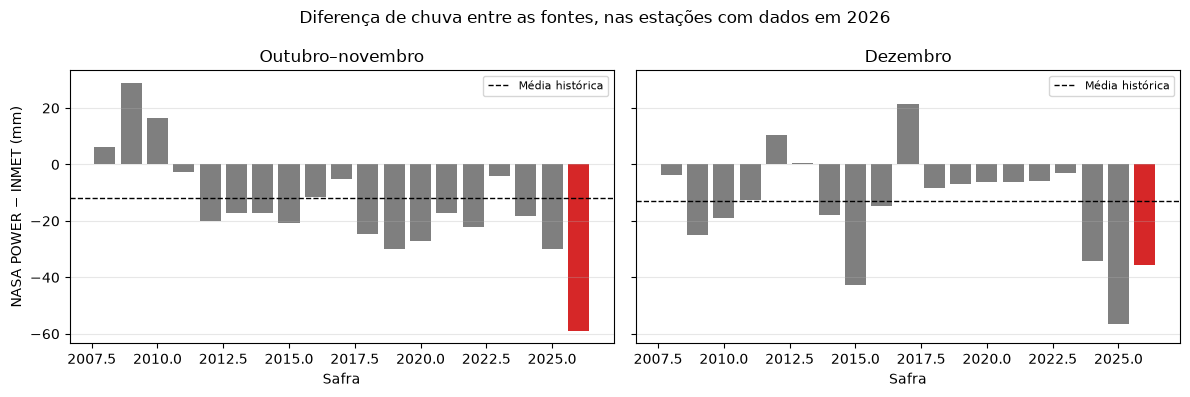

Out–nov/2025: 20 de 23 estações com NASA POWER abaixo do INMET


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (p, titulo) in zip(axes, [("out_nov", "Outubro–novembro"), ("dez", "Dezembro")]):
    r = comparacao[p]
    estacoes_2026 = r.loc[r["ano_safra"] == 2026, "estacao"]
    serie = r[r["estacao"].isin(estacoes_2026) & (r["ano_safra"] >= HISTORICO[0])].groupby("ano_safra")["dif"].mean()
    ax.bar(serie.index, serie, color=["tab:red" if a == 2026 else "tab:grey" for a in serie.index])
    ax.axhline(serie.loc[:HISTORICO[1]].mean(), color="k", ls="--", lw=1, label="Média histórica")
    ax.set_title(titulo)
    ax.set_xlabel("Safra")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("NASA POWER − INMET (mm)")
fig.suptitle("Diferença de chuva entre as fontes, nas estações com dados em 2026")
plt.tight_layout()
plt.show()

por_estacao = comparacao["out_nov"]
atual = por_estacao[por_estacao["ano_safra"] == 2026]
print(f"Out–nov/2025: {(atual['dif'] < 0).sum()} de {len(atual)} estações com NASA POWER abaixo do INMET")

## 4. Quanto isso mudaria a previsão de 2026?

Estimativa de ordem de grandeza com os coeficientes do FL (Etapa 5, seção 10). Soma à chuva do NASA POWER o excesso medido acima e calcula a mudança na previsão, mantendo as demais variáveis. A chuva média de dez–fev de 2026 (281 mm) e a média do treino (379 mm) vêm das Etapas 5 e 6. A referência é a distância até o LSPA de setembro de 2026: 2.734 − 2.097 = 637 kg/ha.

In [5]:
COEF_OUT_NOV, COEF_DEZ_FEV, COEF_DEZ_FEV_2 = -41.55, 379.83, -73.06   # kg/ha por 100 mm
CHUVA_DEZ_FEV_2026, MEDIA_TREINO, DISTANCIA_LSPA = 281, 379, 2734 - 2097


def efeito_out_nov(mm):
    return COEF_OUT_NOV * mm / 100


def efeito_dez_fev(mm):
    x0 = (CHUVA_DEZ_FEV_2026 - MEDIA_TREINO) / 100
    x1 = x0 + mm / 100
    return COEF_DEZ_FEV * (x1 - x0) + COEF_DEZ_FEV_2 * (x1 ** 2 - x0 ** 2)


excesso_out_nov = -resumo.loc["out_nov", "excesso 2026 (mm)"]
excesso_dez = -resumo.loc["dez", "excesso 2026 (mm)"]
efeitos = pd.DataFrame({
    "chuva somada (mm)": [excesso_out_nov, excesso_dez],
    "mudança na previsão (kg/ha)": [efeito_out_nov(excesso_out_nov), efeito_dez_fev(excesso_dez)],
}, index=["Out–nov/2025", "Dez/2025"])
efeitos["% da distância até o LSPA"] = 100 * efeitos["mudança na previsão (kg/ha)"] / DISTANCIA_LSPA
display(efeitos)
faltam = next(mm for mm in range(1, 400) if efeito_dez_fev(mm) + efeito_out_nov(excesso_out_nov) >= DISTANCIA_LSPA)
print(f"Só com a chuva, seriam precisos cerca de {faltam} mm a mais em dez–fev para chegar ao LSPA "
      f"(acima dos {CHUVA_DEZ_FEV_2026} mm do NASA POWER)")

,chuva somada (mm),mudança na previsão (kg/ha),% da distância até o LSPA
Out–nov/2025,47.0,-19.5,-3.1
Dez/2025,22.7,115.2,18.1


Só com a chuva, seriam precisos cerca de 163 mm a mais em dez–fev para chegar ao LSPA (acima dos 281 mm do NASA POWER)


## 5. Conclusões parciais da Etapa 7

**Só avalia out–dez/2025.** O período que mais pesa no FL, dezembro a fevereiro, ainda não pode ser fechado, porque o INMET disponível termina em 31/12/2025. Em 2026 há dados suficientes em apenas 23 estações em out–nov e 18 em dezembro, contra cerca de 40 nas safras recentes.

**1. Em out–nov/2025, o NASA POWER ficou mais seco que as estações além do habitual.** A diferença foi de −59 mm (148 × 207 mm), contra −12 mm em média em 2008–2025, nas mesmas estações, e fora de toda a faixa histórica (a menor foi −30 mm). Em 20 das 23 estações, o NASA POWER ficou abaixo do INMET.

**2. Em dezembro/2025, a diferença está dentro do que já ocorreu.** Foi de −36 mm (148 × 184 mm), contra −13 mm em média e −56 mm no pior ano. O excesso de 23 mm é pequeno diante da variação entre safras (desvio de 18 mm).

**3. Isso não explica a subestimativa de 2026.** O coeficiente da chuva de out–nov é negativo, então corrigi-la **reduziria** a previsão em cerca de 20 kg/ha. A correção de dezembro aumentaria cerca de 115 kg/ha, ou 18% da distância até o LSPA (637 kg/ha). Só pela chuva, seriam precisos cerca de 163 mm a mais em dez–fev, e dezembro só mostra 23 mm. Janeiro e fevereiro ainda podem mudar esse quadro, mas a chuva dificilmente explicará toda a diferença.

**Limites:** a estimativa é de ordem de grandeza e mantém as demais variáveis, como umidade mínima e déficit hídrico. A chuva vem de um ponto (estação) contra a média de uma área (célula de ~50 km), e o FL usa todos os municípios ponderados pela área, não as estações. O resultado também não testa as outras causas possíveis, como manejo, chuva concentrada e a incerteza do próprio LSPA. Pela regra da Etapa 7, nada aqui justifica trocar a fonte de clima por enquanto.

**Próximos passos:**
- Baixar do BDMEP os dados diários de 01/01/2026 a 31/03/2026 das mesmas 45 estações e salvar em `dataset/raw/inmet_estacoes_RS_2026.csv`, com as colunas do arquivo consolidado. O notebook passa a usar o arquivo sozinho e preenche dez–fev e março.
- Estender a comparação à umidade mínima, aos dias de calor e ao déficit hídrico, que também entram no FL.
- Comparar com outra reanálise e aplicar a regra de troca da fonte: só trocar se a nova reduzir o RMSE médio nas duas validações.